In [323]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# import pywt
# import seaborn as sns
# import scipy.stats as stats
# import matplotlib.dates as mdates
# import statsmodels.api as sm
# import statsmodels.robust.norms as robust_norms
# from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# from statsmodels.stats.diagnostic import acorr_ljungbox
# from statsmodels.stats.outliers_influence import OLSInfluence
# from scipy.fft import fft
# from scipy import signal 
# from scipy.stats import linregress
# from scipy.stats import ttest_1samp
# from sklearn.metrics import r2_score
# from scipy.stats import t as t_dist
# from sklearn.decomposition import PCA
# pd.set_option('display.max_columns', None) 

## Value

In [27]:
start_date = '2013-01-04'
end_date = '2023-12-31'

delta = 0.7

## Function

In [ ]:
def assign_quantile_groups(df, value_column, group_column, n_groups=5):
    """
    df: pandas DataFrame。
    value_column: str。
    group_column: str。
    """
    df = df.sort_values(by=[group_column, 's_info_windcode'])

    df[f'{value_column}_porf'] = df.groupby(group_column)[value_column].transform(
        lambda x: pd.qcut(x, n_groups, labels=False, duplicates='drop') + 1
    )
    
    return df


def custom_qcut(series):
    proportions = np.array([1, 2, 2, 2, 1]) / 8.0
    quantiles = np.cumsum(proportions)[:-1] 
    bins = np.quantile(series, quantiles)
    bins = np.insert(bins, 0, -np.inf) 
    bins = np.append(bins, np.inf) 
    return pd.cut(series, bins=bins, labels=False) + 1


# merged_data = pd.merge(
#     MoneyFlow,  
#     Price[['trade_dt', 's_info_windcode', 's_dq_tradestatuscode']],  
#     on=['trade_dt', 's_info_windcode'],  
#     how='left'  
# )

In [ ]:
def backtest(A, B, factor):
    
    StockPicking = pd.merge(A, B, on=['trade_month', 's_info_windcode'], how='left')
    StockPicking = StockPicking.drop_duplicates(subset=['trade_month', 's_info_windcode'])
    StockPicking = StockPicking.sort_values(by=['s_info_windcode', 'trade_month'])
    StockPicking = StockPicking.reset_index(drop=True)

    StockPicking = StockPicking.dropna(subset=['Ret_next_month', factor])

    try:
        if 'exclude' in StockPicking.columns:
            StockPicking = StockPicking[StockPicking['exclude'] != 1]
        elif 'exclude_x' in StockPicking.columns:
            StockPicking = StockPicking[StockPicking['exclude_x'] != 1]
    except:
        pass

    StockPicking = assign_quantile_groups(StockPicking, factor, 'trade_month')    
    
    StockPicking['porf_return'] = StockPicking.groupby(['trade_month', factor+'_porf'])['Ret_next_month'].transform('mean')
    StockPicking = StockPicking.drop_duplicates(subset=['trade_month', factor+'_porf'])

    StockPicking = StockPicking.pivot(index='trade_month', columns=factor+'_porf', values='porf_return')

    StockPicking['5-1_porf'] = StockPicking[5] - StockPicking[1]
    StockPicking['1-5_porf'] = StockPicking[1] - StockPicking[5]
    StockPicking['cumulative_5-1_porf'] = (1 + StockPicking['5-1_porf']).cumprod()
    StockPicking['cumulative_1-5_porf'] = (1 + StockPicking['1-5_porf']).cumprod()

    return StockPicking

## Function TK

In [11]:
def v(x, alpha=0.88, lam=2.25):
    if x >= 0:
        return x**alpha
    else:
        return -lam * ((-x)**alpha)
    
def w_plus(P, gamma=0.61):
    return (P ** gamma) / ((P ** gamma) + ((1 - P) ** gamma))**(1/gamma)

def w_minus(P, delta=0.69):
    return (P ** delta) / ((P ** delta) + ((1 - P) ** delta))**(1/delta)

def calculate_TK_for_month_final(r_values, v, w_minus, w_plus):

    past_returns = r_values[-60:]
    negative_returns = past_returns[past_returns < 0].sort_values()
    positive_returns = past_returns[past_returns > 0].sort_values()
    m = len(negative_returns)
    n = len(positive_returns)

    tk_sum = 0
    
    for i, r_i in zip(range(-m, 0), negative_returns):
        tk_sum += v(r_i) * (w_minus((i + m + 1) / 60) - w_minus((i + m) / 60))
    
    for i, r_i in zip(range(1, n + 1), positive_returns):
        tk_sum += v(r_i) * (w_plus((n - i + 1) / 60) - w_plus((n - i) / 60))
    
    return tk_sum

## Function ST

In [14]:
def calculate_salience_weight(group):

    group['Rank'] = group['Salience'].rank(method='dense', ascending=False)

    denominator = sum(delta ** (group['Rank']) * (1 / len(group)))
    group['Salience_Weight'] = (delta ** group['Rank']) / denominator

    return group

def calculate_st_value(group):

    weighted_return = (group['Salience_Weight'] * group['daily_ret']).sum()

    unweighted_return = (group['Salience_Weight'] * group['daily_ret'] * (1 / len(group))).sum()

    group['ST_value'] = weighted_return - unweighted_return
    
    return group

# def calculate_covariance(group):
#     if len(group) > 1:
#         cov_value = group['Salience_Weight'].cov(group['daily_ret'])
#     else:
#         cov_value = None
#     group['ST_value'] = cov_value
#     return group

## Data set

In [29]:
index = pd.read_csv('index_wgt_data.csv', delimiter=',')

index['TradingDay'] = pd.to_datetime(index['TradingDay'], format='%Y%m%d')

index = index[(index['TradingDay'] >= start_date) & (index['TradingDay'] <= '2023-12-31')]

index.rename(columns={'StockCode': 's_info_windcode'}, inplace=True)
index['trade_month'] = pd.to_datetime(index['TradingDay']).dt.to_period('M')  # Convert to string
index = index.groupby([index['trade_month'], 's_info_windcode'], as_index=False).last()

index = index.drop(columns=['TradingDay'])

index

,trade_month,s_info_windcode,Unnamed: 0,IndexCode,Weight
0,2013-01,000001.SZ,500010,000300.SH,0.9808
1,2013-01,000002.SZ,500011,000300.SH,2.1095
2,2013-01,000006.SZ,1641498,000905.SH,0.3100
3,2013-01,000009.SZ,500012,000300.SH,0.1922
4,2013-01,000012.SZ,500013,000300.SH,0.2063
...,...,...,...,...,...
105458,2023-12,688778.SH,1706662,000905.SH,0.1040
105459,2023-12,688779.SH,1706731,000905.SH,0.1100
105460,2023-12,688819.SH,1706625,000905.SH,0.0590
105461,2023-12,688981.SH,1294336,000300.SH,0.6022


In [31]:
ST_pool = pd.read_csv('st_status.csv', delimiter=',')

ST_pool['entry_dt'] = pd.to_datetime(ST_pool['entry_dt'], format='%Y%m%d')
ST_pool['remove_dt'] = pd.to_datetime(ST_pool['remove_dt'], format='%Y%m%d')
ST_pool['ann_dt'] = pd.to_datetime(ST_pool['ann_dt'], format='%Y%m%d')

ST_pool['remove_dt'] = ST_pool['remove_dt'].fillna(end_date)

ST_pool = ST_pool[(ST_pool['remove_dt'] >= start_date) & (ST_pool['entry_dt'] <= end_date)]

ST_pool

,s_info_windcode,s_type_st,entry_dt,remove_dt,ann_dt
33,000515.SZ,T,2009-05-06,2023-12-31,2009-05-05
39,600357.SH,T,2009-12-29,2023-12-31,2009-12-26
42,600840.SH,T,2009-08-27,2023-12-31,2009-08-25
45,600591.SH,Y,2009-03-26,2023-12-31,2009-03-25
56,000787.SZ,Y,2006-05-09,2013-02-08,2013-02-07
...,...,...,...,...,...
2943,300495.SZ,Y,2023-04-27,2024-09-20,2024-09-19
2944,000806.SZ,T,2023-07-06,2023-12-31,2023-07-06
2945,300089.SZ,T,2023-07-13,2023-12-31,2023-07-13
2946,000023.SZ,S,2023-09-27,2024-09-02,2024-09-02


In [33]:
trade_dates = pd.date_range(start=start_date, end=end_date, freq='B')  # B表示工作日频率

rows = []

for _, row in ST_pool.iterrows():
    stock_code = row['s_info_windcode']
    entry_dt = pd.to_datetime(row['entry_dt'])
    remove_dt = pd.to_datetime(row['remove_dt'])
    
    for trade_date in trade_dates:
        is_st = 1 if entry_dt <= trade_date <= remove_dt else 0
        rows.append({'s_info_windcode': stock_code, 'trade_dt': trade_date, 'is_st': is_st})

result = pd.DataFrame(rows)

result

,s_info_windcode,trade_dt,is_st
0,000515.SZ,2013-01-04,1
1,000515.SZ,2013-01-07,1
2,000515.SZ,2013-01-08,1
3,000515.SZ,2013-01-09,1
4,000515.SZ,2013-01-10,1
...,...,...,...
5009763,300526.SZ,2023-12-25,1
5009764,300526.SZ,2023-12-26,1
5009765,300526.SZ,2023-12-27,1
5009766,300526.SZ,2023-12-28,1


In [35]:
Price = pd.read_csv('ashareeodprice.csv', delimiter=',')

Price = Price[~Price['s_info_windcode'].str.contains('BJ')]

Price['trade_dt'] = pd.to_datetime(Price['trade_dt'], format='%Y%m%d')
Price['trade_month'] = Price['trade_dt'].dt.to_period('M')
Price = Price[(Price['trade_dt'] >= start_date) & (Price['trade_dt'] <= end_date)]

Price = Price.sort_values(by=['s_info_windcode', 'trade_dt'])
Price = Price.drop_duplicates(subset=['s_info_windcode', 'trade_dt'])

stock_counts0 = Price.groupby('s_info_windcode').size()
valid_stocks0 = stock_counts0[stock_counts0 >= 60].index
Price = Price[Price['s_info_windcode'].isin(valid_stocks0)]

columns_to_adjust = ['s_dq_open', 's_dq_close', 's_dq_high', 's_dq_low', 's_dq_limit', 's_dq_stopping']
Price[columns_to_adjust] = Price[columns_to_adjust].mul(Price['s_dq_adjfactor'], axis=0)

Price['20_ret'] = Price.groupby('s_info_windcode')['s_dq_close'].apply(lambda x: x.pct_change(20)).reset_index(level=0, drop=True)

Price = Price[Price['s_dq_tradestatuscode'] != 1]

Price

,trade_dt,s_info_windcode,s_dq_open,s_dq_high,s_dq_low,s_dq_close,s_dq_adjfactor,s_dq_volume,s_dq_amount,s_dq_limit,s_dq_stopping,s_dq_tradestatuscode,trade_month,20_ret
233362,2013-01-04,000001.SZ,590.347995,595.050522,575.878681,578.410811,36.173284,443851.37,717567.5466,637.373264,521.618755,-1.0,2013-01,NaN
233363,2013-01-07,000001.SZ,578.049078,591.433193,574.431750,589.624529,36.173284,357169.25,578450.4876,636.288066,520.533557,-1.0,2013-01,NaN
233364,2013-01-08,000001.SZ,589.624529,592.156659,573.708284,578.772544,36.173284,312479.12,501360.0937,648.586982,530.662076,-1.0,2013-01,NaN
233365,2013-01-09,000001.SZ,577.325613,579.496010,571.537887,573.708284,36.173284,251329.15,399696.1831,636.649798,520.895290,-1.0,2013-01,NaN
233368,2013-01-10,000001.SZ,573.708284,582.389872,571.176154,574.070017,36.173284,240030.27,383347.7326,631.223806,516.192763,-1.0,2013-01,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10197032,2023-12-25,689009.SH,30.850000,31.200000,30.060000,30.080000,1.000000,35911.21,109649.3980,37.270000,24.850000,-1.0,2023-12,-0.137862
10199760,2023-12-26,689009.SH,30.140000,30.250000,26.000000,27.850000,1.000000,90422.96,251945.4740,36.100000,24.060000,-1.0,2023-12,-0.189464
10200246,2023-12-27,689009.SH,27.900000,28.890000,27.180000,28.890000,1.000000,54888.47,155156.3810,33.420000,22.280000,-1.0,2023-12,-0.131650
10200621,2023-12-28,689009.SH,28.580000,29.850000,28.440000,29.200000,1.000000,50272.47,147201.1330,34.670000,23.110000,-1.0,2023-12,-0.117825


In [37]:
Price1 = pd.merge(Price, result, on=['s_info_windcode', 'trade_dt'], how='left')

Price1 = Price1.drop_duplicates(subset=['s_info_windcode', 'trade_dt'])

Price1['is_st'] = Price1['is_st'].fillna(0).astype(int)

Price1['limit_stop'] = ((Price1['s_dq_high'] == Price1['s_dq_close']) & (Price1['s_dq_close'] == Price1['s_dq_limit'])) | \
                        ((Price1['s_dq_low'] == Price1['s_dq_close']) & (Price1['s_dq_close'] == Price1['s_dq_stopping']))

Price1['limit_stop'] = Price1['limit_stop'].astype(int)

Price1['exclude'] = ((Price1['is_st'] != 0) | (Price1['limit_stop'] != 0)).astype(int)

Price1

,trade_dt,s_info_windcode,s_dq_open,s_dq_high,s_dq_low,s_dq_close,s_dq_adjfactor,s_dq_volume,s_dq_amount,s_dq_limit,s_dq_stopping,s_dq_tradestatuscode,trade_month,20_ret,is_st,limit_stop,exclude
0,2013-01-04,000001.SZ,590.347995,595.050522,575.878681,578.410811,36.173284,443851.37,717567.5466,637.373264,521.618755,-1.0,2013-01,NaN,0,0,0
1,2013-01-07,000001.SZ,578.049078,591.433193,574.431750,589.624529,36.173284,357169.25,578450.4876,636.288066,520.533557,-1.0,2013-01,NaN,0,0,0
2,2013-01-08,000001.SZ,589.624529,592.156659,573.708284,578.772544,36.173284,312479.12,501360.0937,648.586982,530.662076,-1.0,2013-01,NaN,0,0,0
3,2013-01-09,000001.SZ,577.325613,579.496010,571.537887,573.708284,36.173284,251329.15,399696.1831,636.649798,520.895290,-1.0,2013-01,NaN,0,0,0
4,2013-01-10,000001.SZ,573.708284,582.389872,571.176154,574.070017,36.173284,240030.27,383347.7326,631.223806,516.192763,-1.0,2013-01,NaN,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11738975,2023-12-25,689009.SH,30.850000,31.200000,30.060000,30.080000,1.000000,35911.21,109649.3980,37.270000,24.850000,-1.0,2023-12,-0.137862,0,0,0
11738976,2023-12-26,689009.SH,30.140000,30.250000,26.000000,27.850000,1.000000,90422.96,251945.4740,36.100000,24.060000,-1.0,2023-12,-0.189464,0,0,0
11738977,2023-12-27,689009.SH,27.900000,28.890000,27.180000,28.890000,1.000000,54888.47,155156.3810,33.420000,22.280000,-1.0,2023-12,-0.131650,0,0,0
11738978,2023-12-28,689009.SH,28.580000,29.850000,28.440000,29.200000,1.000000,50272.47,147201.1330,34.670000,23.110000,-1.0,2023-12,-0.117825,0,0,0


In [39]:
monthly_data = Price1.groupby(['s_info_windcode', 'trade_month']).agg(
    first_day_open=('s_dq_open', 'first')
).reset_index()

monthly_data['next_month_open'] = monthly_data.groupby('s_info_windcode')['first_day_open'].shift(-1)
monthly_data['Return'] = (monthly_data['next_month_open'] / monthly_data['first_day_open']) - 1

monthly_data = monthly_data.dropna(subset=['Return'])

monthly_data

,s_info_windcode,trade_month,first_day_open,next_month_open,Return
0,000001.SZ,2013-01,590.347995,760.362430,0.287990
1,000001.SZ,2013-02,760.362430,829.453402,0.090866
2,000001.SZ,2013-03,829.453402,730.700337,-0.119058
3,000001.SZ,2013-04,730.700337,672.823082,-0.079208
4,000001.SZ,2013-05,672.823082,757.106834,0.125269
...,...,...,...,...,...
469609,689009.SH,2023-07,36.950000,34.700000,-0.060893
469610,689009.SH,2023-08,34.700000,33.430000,-0.036599
469611,689009.SH,2023-09,33.430000,34.830000,0.041879
469612,689009.SH,2023-10,34.830000,32.740000,-0.060006


In [41]:
# Monthly return

PriceMonthly = Price1.merge(monthly_data[['s_info_windcode', 'trade_month', 'Return']], 
                    on=['s_info_windcode', 'trade_month'], 
                    how='left')

PriceMonthly = PriceMonthly.dropna(subset=['Return'])
PriceMonthly = PriceMonthly.groupby([PriceMonthly['trade_dt'].dt.to_period('M'), 's_info_windcode'], as_index=False).last()
PriceMonthly = PriceMonthly.drop(columns=['trade_dt'])

PriceMonthly['Ret_next_month'] = PriceMonthly.groupby('s_info_windcode')['Return'].shift(-1)

PriceMonthly

,s_info_windcode,s_dq_open,s_dq_high,s_dq_low,s_dq_close,s_dq_adjfactor,s_dq_volume,s_dq_amount,s_dq_limit,s_dq_stopping,s_dq_tradestatuscode,trade_month,20_ret,is_st,limit_stop,exclude,Return,Ret_next_month
0,000001.SZ,769.405751,771.937881,752.404307,763.256292,36.173284,415884.20,8.739029e+05,848.625243,694.527053,-1.0,2013-01,NaN,0,0,0,0.287990,0.090866
1,000002.SZ,1449.160474,1453.760983,1374.402195,1381.302959,115.012736,1513077.95,1.847784e+06,1603.277540,1311.145190,-1.0,2013-01,NaN,0,0,0,0.190711,-0.003320
2,000004.SZ,38.525412,39.175630,37.631362,37.875194,4.063862,42286.28,3.992242e+04,43.198853,35.314961,-1.0,2013-01,NaN,0,0,0,0.137973,0.079399
3,000005.SZ,29.656330,29.841682,28.544217,28.729569,9.267603,146833.60,4.572539e+04,32.529287,26.598021,-1.0,2013-01,NaN,0,0,0,0.046823,-0.041534
4,000006.SZ,162.519995,164.529959,157.064377,158.787203,28.713780,215352.27,1.202171e+05,179.173987,146.440278,-1.0,2013-01,NaN,0,0,0,0.105578,-0.063063
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
464389,688799.SH,46.762235,47.159766,46.343781,47.128382,1.046135,8200.74,3.669426e+04,56.104220,37.399326,-1.0,2023-11,-0.042915,0,0,0,-0.042735,NaN
464390,688800.SH,62.578217,63.214606,60.669051,61.871119,1.414197,14619.32,6.372822e+04,75.546404,50.373697,-1.0,2023-11,0.151013,0,0,0,0.110406,NaN
464391,688819.SH,31.126066,31.482992,30.958101,31.073577,1.049783,12525.06,3.712421e+04,37.613725,25.079316,-1.0,2023-11,-0.069767,0,0,0,-0.077594,NaN
464392,688981.SH,53.760000,54.190000,53.450000,53.700000,1.000000,107828.74,5.801689e+05,64.440000,42.960000,-1.0,2023-11,-0.062991,0,0,0,-0.061953,NaN


In [45]:
MoneyFlow0 = pd.read_csv('asharemoneyflow.csv', delimiter=',')

MoneyFlow0 = MoneyFlow0[~MoneyFlow0['s_info_windcode'].str.contains('BJ')]

MoneyFlow0 = MoneyFlow0.drop_duplicates(subset=['s_info_windcode', 'trade_dt'])

MoneyFlow0['trade_dt'] = pd.to_datetime(MoneyFlow0['trade_dt'], format='%Y%m%d')
MoneyFlow0 = MoneyFlow0.sort_values(by=['s_info_windcode', 'trade_dt'])

MoneyFlow0 = MoneyFlow0[(MoneyFlow0['trade_dt'] >= start_date) & (MoneyFlow0['trade_dt'] <= '2023-12-31')]

MoneyFlow0

,trade_dt,s_info_windcode,buy_value_exlarge_order,sell_value_exlarge_order,buy_value_large_order,sell_value_large_order,buy_value_med_order,sell_value_med_order,buy_value_small_order,sell_value_small_order
2017646,2013-01-04,000001.SZ,22520.2019,25850.0970,21890.9224,17804.9390,16796.9465,17280.1462,10520.6130,10793.5016
1960564,2013-01-07,000001.SZ,20437.2064,19972.3716,16981.7037,12836.7137,11986.1800,14772.7326,8359.3614,10182.6336
1969787,2013-01-08,000001.SZ,8969.1490,13848.2079,15460.5613,13951.9368,13931.3994,12439.3070,11710.7969,9832.4549
1998113,2013-01-09,000001.SZ,8556.8945,10286.1352,11689.0415,11831.8151,10241.3311,9988.9240,9447.2140,7827.6068
1957598,2013-01-10,000001.SZ,11797.3841,9785.7227,8962.5836,9500.1390,9580.6207,10459.0733,7945.9677,8541.6211
...,...,...,...,...,...,...,...,...,...,...
10640401,2023-12-25,688981.SH,5519.9319,6819.8318,25542.9391,24839.8625,36298.7033,29625.7631,28050.4523,34126.5692
10634655,2023-12-26,688981.SH,2202.6505,4445.5606,19058.0075,17642.9240,30330.5431,25458.1065,23820.2320,27864.8420
10630726,2023-12-27,688981.SH,6191.0358,8406.9381,23258.5831,19960.6686,28010.2478,24617.8256,21185.2700,25659.7044
10565127,2023-12-28,688981.SH,8752.7334,6160.6094,30537.0878,33425.7864,34725.1572,35991.1713,27512.4720,25949.8834


In [47]:
MoneyFlow = pd.merge(
    MoneyFlow0,
    Price1[['trade_dt', 's_info_windcode', 'exclude']],
    on=['trade_dt', 's_info_windcode'],
    how='left'
)

MoneyFlow = MoneyFlow.drop_duplicates(subset=['s_info_windcode', 'trade_dt'])

stock_counts1 = MoneyFlow.groupby('s_info_windcode').size()
valid_stocks1 = stock_counts1[stock_counts1 >= 60].index
MoneyFlow = MoneyFlow[MoneyFlow['s_info_windcode'].isin(valid_stocks1)]

MoneyFlow['exclude'] = MoneyFlow['exclude'].fillna(0).astype(int)

MoneyFlow['net_ex_large'] = MoneyFlow['buy_value_exlarge_order'] - MoneyFlow['sell_value_exlarge_order']
MoneyFlow['net_large'] = MoneyFlow['buy_value_large_order'] - MoneyFlow['sell_value_large_order']
MoneyFlow['net_med'] = MoneyFlow['buy_value_med_order'] - MoneyFlow['sell_value_med_order']
MoneyFlow['net_small'] = MoneyFlow['buy_value_small_order'] - MoneyFlow['sell_value_small_order']

MoneyFlow

,trade_dt,s_info_windcode,buy_value_exlarge_order,sell_value_exlarge_order,buy_value_large_order,sell_value_large_order,buy_value_med_order,sell_value_med_order,buy_value_small_order,sell_value_small_order,exclude,net_ex_large,net_large,net_med,net_small
0,2013-01-04,000001.SZ,22520.2019,25850.0970,21890.9224,17804.9390,16796.9465,17280.1462,10520.6130,10793.5016,0,-3329.8951,4085.9834,-483.1997,-272.8886
1,2013-01-07,000001.SZ,20437.2064,19972.3716,16981.7037,12836.7137,11986.1800,14772.7326,8359.3614,10182.6336,0,464.8348,4144.9900,-2786.5526,-1823.2722
2,2013-01-08,000001.SZ,8969.1490,13848.2079,15460.5613,13951.9368,13931.3994,12439.3070,11710.7969,9832.4549,0,-4879.0589,1508.6245,1492.0924,1878.3420
3,2013-01-09,000001.SZ,8556.8945,10286.1352,11689.0415,11831.8151,10241.3311,9988.9240,9447.2140,7827.6068,0,-1729.2407,-142.7736,252.4071,1619.6072
4,2013-01-10,000001.SZ,11797.3841,9785.7227,8962.5836,9500.1390,9580.6207,10459.0733,7945.9677,8541.6211,0,2011.6614,-537.5554,-878.4526,-595.6534
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9147788,2023-12-25,688981.SH,5519.9319,6819.8318,25542.9391,24839.8625,36298.7033,29625.7631,28050.4523,34126.5692,0,-1299.8999,703.0766,6672.9402,-6076.1169
9147789,2023-12-26,688981.SH,2202.6505,4445.5606,19058.0075,17642.9240,30330.5431,25458.1065,23820.2320,27864.8420,0,-2242.9101,1415.0835,4872.4366,-4044.6100
9147790,2023-12-27,688981.SH,6191.0358,8406.9381,23258.5831,19960.6686,28010.2478,24617.8256,21185.2700,25659.7044,0,-2215.9023,3297.9145,3392.4222,-4474.4344
9147791,2023-12-28,688981.SH,8752.7334,6160.6094,30537.0878,33425.7864,34725.1572,35991.1713,27512.4720,25949.8834,0,2592.1240,-2888.6986,-1266.0141,1562.5886


In [51]:
# Calculate 3 factors each day

ThreeFactor = MoneyFlow.copy()

# Amount factor
ThreeFactor['total'] = ( ThreeFactor['buy_value_exlarge_order'] + ThreeFactor['buy_value_large_order']
                       + ThreeFactor['buy_value_med_order'] + ThreeFactor['buy_value_small_order']
)

ThreeFactor['large_factor'] = ThreeFactor.groupby('s_info_windcode').apply(
    lambda x: x['net_large'].rolling(window=20).sum() / x['total'].rolling(window=20).sum()
).reset_index(level=0, drop=True)

ThreeFactor['small_factor'] = ThreeFactor.groupby('s_info_windcode').apply(
    lambda x: x['net_small'].rolling(window=20).sum() / x['total'].rolling(window=20).sum()
).reset_index(level=0, drop=True)

# Buy + sell factor
ThreeFactor['large_total'] = ThreeFactor['buy_value_large_order'] + ThreeFactor['sell_value_large_order']
ThreeFactor['small_total'] = ThreeFactor['buy_value_small_order'] + ThreeFactor['sell_value_small_order']

ThreeFactor['large_factor1'] = ThreeFactor.groupby('s_info_windcode').apply(
    lambda x: x['net_large'].rolling(window=20).sum() / x['large_total'].rolling(window=20).sum()
).reset_index(level=0, drop=True)

ThreeFactor['small_factor1'] = ThreeFactor.groupby('s_info_windcode').apply(
    lambda x: x['net_small'].rolling(window=20).sum() / x['small_total'].rolling(window=20).sum()
).reset_index(level=0, drop=True)

# Absolute factor
ThreeFactor['large_absolute'] = (ThreeFactor['buy_value_large_order'] - ThreeFactor['sell_value_large_order']).abs()
ThreeFactor['small_absolute'] = (ThreeFactor['buy_value_small_order'] - ThreeFactor['sell_value_small_order']).abs()

ThreeFactor['large_factor2'] = ThreeFactor.groupby('s_info_windcode').apply(
    lambda x: x['net_large'].rolling(window=20).sum() / x['large_absolute'].rolling(window=20).sum()
).reset_index(level=0, drop=True)

ThreeFactor['small_factor2'] = ThreeFactor.groupby('s_info_windcode').apply(
    lambda x: x['net_small'].rolling(window=20).sum() / x['small_absolute'].rolling(window=20).sum()
).reset_index(level=0, drop=True)

# ThreeFactor['factor2'] = ThreeFactor['large_factor2'] + ThreeFactor['small_factor2']

ThreeFactor = ThreeFactor.dropna(subset=['large_factor', 'small_factor'])

# ThreeFactor['absolute'] = (ThreeFactor['buy_value_large_order'] - ThreeFactor['sell_value_large_order'] - ThreeFactor['sell_value_small_order'] + ThreeFactor['buy_value_small_order']).abs()

# ThreeFactor['factor1'] = ThreeFactor.groupby('s_info_windcode').apply(
#     lambda x: (x['net_large'] - x['net_small']).rolling(window=20).sum() / x['absolute'].rolling(window=20).sum()
# ).reset_index(level=0, drop=True)

ThreeFactor = ThreeFactor.drop(columns=['buy_value_exlarge_order', 'sell_value_exlarge_order', 'buy_value_large_order', 
                                      'sell_value_large_order', 'buy_value_med_order', 'sell_value_med_order', 'buy_value_small_order', 
                                      'sell_value_small_order', 'net_ex_large', 'net_large', 'net_med', 'net_small', 
                                      'total', 'large_total', 'small_total', 'large_absolute', 'small_absolute'])

ThreeFactor

C:\Users\yangh\AppData\Local\Temp\ipykernel_7932\4231112412.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ThreeFactor['large_factor'] = ThreeFactor.groupby('s_info_windcode').apply(
C:\Users\yangh\AppData\Local\Temp\ipykernel_7932\4231112412.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ThreeFactor['small_factor'] = ThreeFactor.groupby('s_info_windcode').apply(
C:\Users\yangh\AppData\Local\Temp\ipykerne

,trade_dt,s_info_windcode,exclude,large_factor,small_factor,large_factor1,small_factor1,large_factor2,small_factor2
19,2013-01-31,000001.SZ,0,0.001266,-0.011980,0.002191,-0.036779,0.063459,-0.430726
20,2013-02-01,000001.SZ,0,-0.002038,-0.012975,-0.003522,-0.039451,-0.106427,-0.461060
21,2013-02-04,000001.SZ,0,-0.003703,-0.010099,-0.006345,-0.030957,-0.219533,-0.365639
22,2013-02-05,000001.SZ,0,-0.005494,-0.009844,-0.009389,-0.030150,-0.316752,-0.360813
23,2013-02-06,000001.SZ,0,-0.005026,-0.009347,-0.008535,-0.028725,-0.289548,-0.343552
...,...,...,...,...,...,...,...,...,...
9147788,2023-12-25,688981.SH,0,-0.012905,0.029315,-0.022110,0.059375,-0.417495,0.686005
9147789,2023-12-26,688981.SH,0,-0.006646,0.020566,-0.011450,0.041171,-0.252962,0.535103
9147790,2023-12-27,688981.SH,0,-0.002422,0.014137,-0.004182,0.028058,-0.094623,0.383838
9147791,2023-12-28,688981.SH,0,-0.003571,0.013347,-0.006130,0.026453,-0.136243,0.375786


In [52]:
# Only remain the last day of each month

ThreeFactorMonthly = ThreeFactor.copy()

ThreeFactorMonthly['trade_month'] = ThreeFactorMonthly['trade_dt'].dt.to_period('M')
ThreeFactorMonthly = ThreeFactorMonthly.groupby([ThreeFactorMonthly['trade_dt'].dt.to_period('M'), 's_info_windcode'], as_index=False).last()
ThreeFactorMonthly = ThreeFactorMonthly.drop(columns=['trade_dt'])

ThreeFactorMonthly

,s_info_windcode,exclude,large_factor,small_factor,large_factor1,small_factor1,large_factor2,small_factor2,trade_month
0,000001.SZ,0,0.001266,-0.011980,0.002191,-0.036779,0.063459,-0.430726,2013-01
1,000004.SZ,0,-0.012220,0.010571,-0.045558,0.011898,-0.210799,0.169787,2013-01
2,000005.SZ,0,-0.018850,0.004941,-0.064670,0.005061,-0.428923,0.074983,2013-01
3,000006.SZ,0,-0.007478,0.001910,-0.015260,0.002820,-0.224489,0.058804,2013-01
4,000008.SZ,1,-0.021354,-0.002355,-0.065493,-0.002922,-0.300836,-0.032202,2013-01
...,...,...,...,...,...,...,...,...,...
456665,688798.SH,0,-0.010322,0.023536,-0.047304,0.019581,-0.303699,0.493420,2023-12
456666,688799.SH,0,-0.035391,0.028211,-0.075953,0.036142,-0.448539,0.363952,2023-12
456667,688800.SH,0,0.010060,-0.023224,0.031207,-0.024874,0.231954,-0.391133,2023-12
456668,688819.SH,0,0.001265,-0.009960,0.007327,-0.007853,0.034570,-0.180863,2023-12


In [293]:
StockPicking7 = backtest(ThreeFactorMonthly, PriceMonthly, 'large_factor2')

StockPicking7

large_factor2_porf,1,2,3,4,5,5-1_porf,1-5_porf,cumulative_5-1_porf,cumulative_1-5_porf
trade_month,,,,,,,,,
2013-01,0.044228,0.036946,0.038081,0.040744,0.040535,-0.003693,0.003693,0.996307,1.003693
2013-02,-0.049936,-0.053141,-0.033583,-0.028723,-0.015346,0.034590,-0.034590,1.030769,0.968976
2013-03,-0.039707,-0.038476,-0.031332,-0.031978,-0.018401,0.021306,-0.021306,1.052731,0.948330
2013-04,0.142344,0.152271,0.147197,0.151355,0.147415,0.005072,-0.005072,1.058070,0.943521
2013-05,-0.169052,-0.159550,-0.165340,-0.148243,-0.138054,0.030998,-0.030998,1.090868,0.914273
...,...,...,...,...,...,...,...,...,...
2023-06,0.005482,0.005929,0.009499,0.013753,0.007857,0.002376,-0.002376,4.550690,0.203829
2023-07,-0.041014,-0.036101,-0.033430,-0.033616,-0.043322,-0.002308,0.002308,4.540186,0.204300
2023-08,-0.009538,-0.005788,-0.000135,-0.000436,-0.006325,0.003213,-0.003213,4.554773,0.203644


In [295]:
StockPicking8 = backtest(ThreeFactorMonthly, PriceMonthly, 'small_factor2')
StockPicking8

small_factor2_porf,1,2,3,4,5,5-1_porf,1-5_porf,cumulative_5-1_porf,cumulative_1-5_porf
trade_month,,,,,,,,,
2013-01,0.038456,0.036750,0.039092,0.040678,0.045558,0.007101,-0.007101,1.007101,0.992899
2013-02,-0.013747,-0.036160,-0.040329,-0.043393,-0.047177,-0.033430,0.033430,0.973434,1.026091
2013-03,-0.022070,-0.030040,-0.036528,-0.035573,-0.035673,-0.013604,0.013604,0.960191,1.040050
2013-04,0.149331,0.148342,0.146685,0.155498,0.140725,-0.008606,0.008606,0.951928,1.049001
2013-05,-0.137753,-0.149787,-0.154285,-0.171708,-0.166735,-0.028982,0.028982,0.924339,1.079404
...,...,...,...,...,...,...,...,...,...
2023-06,0.004631,0.008865,0.009080,0.003029,0.016914,0.012283,-0.012283,0.428604,2.176659
2023-07,-0.036749,-0.031390,-0.034993,-0.036955,-0.047397,-0.010649,0.010649,0.424040,2.199837
2023-08,-0.002145,-0.007057,-0.008434,-0.002281,-0.002313,-0.000167,0.000167,0.423969,2.200206


## TK

In [309]:
TK = pd.merge(
    ThreeFactorMonthly,
    PriceMonthly[['trade_month', 's_info_windcode', 'Return']],
    on=['trade_month', 's_info_windcode'],
    how='left'
)

TK['Return_next_month'] = TK.groupby('s_info_windcode')['Return'].shift(-1)
TK = TK.dropna(subset=['Return_next_month'])

TK['TK'] = TK.groupby('s_info_windcode')['Return'].transform(lambda x: x.rolling(window=60, min_periods=60)
                                                        .apply(lambda x: calculate_TK_for_month_final(x, v, w_minus, w_plus), raw=False))

TK = TK.dropna(subset=['TK'])

TK = TK[TK['exclude'] != 1]

TK

,s_info_windcode,exclude,large_factor,small_factor,large_factor1,small_factor1,large_factor2,small_factor2,trade_month,Return,Return_next_month,TK
153614,000001.SZ,0,0.000546,0.023965,0.000984,0.104362,0.017691,0.510907,2017-12,-0.003731,0.044944,-0.038025
153621,000011.SZ,0,-0.023889,0.053008,-0.068680,0.068677,-0.300217,0.520409,2017-12,-0.012881,0.000000,-0.065534
153622,000012.SZ,0,-0.039780,0.067365,-0.063471,0.152031,-0.813303,0.905921,2017-12,-0.083516,0.043165,-0.037112
153623,000014.SZ,0,-0.000170,0.085090,-0.000466,0.139670,-0.002166,0.967362,2017-12,-0.136910,0.113173,-0.057523
153628,000021.SZ,0,-0.023935,0.017630,-0.041887,0.035316,-0.387552,0.244316,2017-12,0.087100,-0.094320,-0.058359
...,...,...,...,...,...,...,...,...,...,...,...,...
445865,603991.SH,0,-0.042639,0.064282,-0.097426,0.069479,-0.513155,0.874277,2023-10,-0.017780,0.475590,-0.023912
445867,603993.SH,0,-0.014469,0.006481,-0.031053,0.009064,-0.385058,0.120215,2023-10,-0.059524,-0.057866,-0.051668
445869,603997.SH,0,-0.012229,0.001725,-0.056311,0.001448,-0.221912,0.026925,2023-10,-0.006102,-0.036153,-0.045729
445870,603998.SH,0,0.004371,0.003009,0.017584,0.002847,0.185861,0.056620,2023-10,0.002427,0.006381,-0.035626


In [310]:
singleTK = backtest(TK, PriceMonthly, 'TK')

singleTK

TK_porf,1,2,3,4,5,5-1_porf,1-5_porf,cumulative_5-1_porf,cumulative_1-5_porf
trade_month,,,,,,,,,
2017-12,-0.018070,-0.019481,-0.009664,0.015064,-0.000965,0.017105,-0.017105,1.017105,0.982895
2018-01,-0.060062,-0.058241,-0.048322,-0.046756,-0.045451,0.014611,-0.014611,1.031966,0.968534
2018-02,0.050701,0.045002,0.042166,0.022422,0.014896,-0.035805,0.035805,0.995016,1.003213
2018-03,-0.051110,-0.049634,-0.040734,-0.038340,-0.041190,0.009921,-0.009921,1.004887,0.993260
2018-04,-0.019590,-0.014184,-0.011929,-0.008408,-0.013229,0.006362,-0.006362,1.011280,0.986941
...,...,...,...,...,...,...,...,...,...
2023-06,0.039603,0.023837,0.023078,0.022383,-0.003098,-0.042701,0.042701,0.518124,1.799179
2023-07,-0.036593,-0.044742,-0.050292,-0.055253,-0.052429,-0.015837,0.015837,0.509919,1.827672
2023-08,0.006901,0.000133,0.006353,-0.004204,-0.002902,-0.009803,0.009803,0.504920,1.845588


In [189]:
TK_port = TK.copy()

TK_port['TK_Porf'] = TK_port.groupby('trade_month')['TK'].transform(custom_qcut)
TK_port['large_factor2_Porf'] = TK_port.groupby(['trade_month', 'TK_Porf'])['large_factor2'].transform(lambda x: pd.qcut(x, q=5, labels=False) + 1)
TK_port['small_factor2_Porf'] = TK_port.groupby(['trade_month', 'TK_Porf'])['small_factor2'].transform(lambda x: pd.qcut(x, q=5, labels=False) + 1)

TK_port

,s_info_windcode,exclude,large_factor,small_factor,large_factor1,small_factor1,large_factor2,small_factor2,trade_month,Return,Return_next_month,TK,TK_Porf,large_factor2_Porf,small_factor2_Porf
153614,000001.SZ,0,0.000546,0.023965,0.000984,0.104362,0.017691,0.510907,2017-12,-0.003731,0.044944,-0.038025,4,5,3
153621,000011.SZ,0,-0.023889,0.053008,-0.068680,0.068677,-0.300217,0.520409,2017-12,-0.012881,0.000000,-0.065534,2,4,3
153622,000012.SZ,0,-0.039780,0.067365,-0.063471,0.152031,-0.813303,0.905921,2017-12,-0.083516,0.043165,-0.037112,4,1,5
153623,000014.SZ,0,-0.000170,0.085090,-0.000466,0.139670,-0.002166,0.967362,2017-12,-0.136910,0.113173,-0.057523,3,5,5
153628,000021.SZ,0,-0.023935,0.017630,-0.041887,0.035316,-0.387552,0.244316,2017-12,0.087100,-0.094320,-0.058359,3,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445865,603991.SH,0,-0.042639,0.064282,-0.097426,0.069479,-0.513155,0.874277,2023-10,-0.017780,0.475590,-0.023912,5,2,5
445867,603993.SH,0,-0.014469,0.006481,-0.031053,0.009064,-0.385058,0.120215,2023-10,-0.059524,-0.057866,-0.051668,3,3,2
445869,603997.SH,0,-0.012229,0.001725,-0.056311,0.001448,-0.221912,0.026925,2023-10,-0.006102,-0.036153,-0.045729,3,3,2
445870,603998.SH,0,0.004371,0.003009,0.017584,0.002847,0.185861,0.056620,2023-10,0.002427,0.006381,-0.035626,4,5,2


In [195]:
TK_port1 = TK_port.copy()

TK_port1 = TK_port1.drop(columns=['s_info_windcode', 'exclude', 'large_factor', 'large_factor1', 'large_factor2',
                                  'small_factor', 'small_factor1', 'small_factor2', 'Return', 'TK'])

TK_port1['large_Port_Return'] = TK_port1.groupby(['trade_month', 'TK_Porf', 'large_factor2_Porf'])['Return_next_month'].transform('mean')
TK_port1['small_Port_Return'] = TK_port1.groupby(['trade_month', 'TK_Porf', 'small_factor2_Porf'])['Return_next_month'].transform('mean')

TK_port1

,trade_month,Return_next_month,TK_Porf,large_factor2_Porf,small_factor2_Porf,large_Port_Return,small_Port_Return
153614,2017-12,0.044944,4,5,3,0.031446,0.021816
153621,2017-12,0.000000,2,4,3,-0.018464,-0.036994
153622,2017-12,0.043165,4,1,5,0.006402,0.004732
153623,2017-12,0.113173,3,5,5,0.011085,-0.011517
153628,2017-12,-0.094320,3,3,2,-0.007509,-0.008651
...,...,...,...,...,...,...,...
445865,2023-10,0.475590,5,2,5,0.044924,0.044655
445867,2023-10,-0.057866,3,3,2,0.032959,0.018008
445869,2023-10,-0.036153,3,3,2,0.032959,0.018008
445870,2023-10,0.006381,4,5,2,0.023700,0.025591


In [197]:
TK_port2 = TK_port1.drop_duplicates(subset=['trade_month', 'TK_Porf', 'large_factor2_Porf'])

TK_port2['large_factor2_Porf'] = (
    TK_port2['TK_Porf'].astype(str) + '-' + TK_port2['large_factor2_Porf'].astype(str)
)

TK_port2 = TK_port2.drop(columns=['Return_next_month', 'small_factor2_Porf', 'small_Port_Return', 'TK_Porf'])
    
TK_port2

C:\Users\yangh\AppData\Local\Temp\ipykernel_7932\2762649005.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  TK_port2['large_factor2_Porf'] = (


,trade_month,large_factor2_Porf,large_Port_Return
153614,2017-12,4-5,0.031446
153621,2017-12,2-4,-0.018464
153622,2017-12,4-1,0.006402
153623,2017-12,3-5,0.011085
153628,2017-12,3-3,-0.007509
...,...,...,...
441543,2023-10,5-4,0.023777
441553,2023-10,2-5,0.031877
441594,2023-10,1-2,0.042361
441627,2023-10,5-3,0.041628


In [239]:
TK_port3 = TK_port2.copy()

TK_port3 = TK_port3.pivot(index='trade_month', columns='large_factor2_Porf', values='large_Port_Return')

TK_port3[1] = TK_port3['1-5'] - TK_port3['5-1']

cumulative_porf_return = TK_port3.apply(lambda x: (1 + x).cumprod().iloc[-1], axis=0)

TK_port3.loc['Cumulative_porf_return'] = cumulative_porf_return

average_return = TK_port3.drop('Cumulative_porf_return', axis=0).mean()

TK_port3.loc['Average_return'] = average_return

t_values = []

for col in TK_port3.columns:
    data = TK_port3[col].drop(index=['Cumulative_porf_return', 'Average_return'], errors='ignore')
        
    x_bar = np.mean(data)
    s = np.std(data, ddof=1)
    n = len(data)
        
    t_stat = (x_bar - 0) / s * np.sqrt(n)
        
    t_values.append(t_stat)

TK_port3.loc['T_value'] = t_values

TK_port3

large_factor2_Porf,1-1,1-2,1-3,1-4,1-5,2-1,2-2,2-3,2-4,2-5,3-1,3-2,3-3,3-4,3-5,4-1,4-2,4-3,4-4,4-5,5-1,5-2,5-3,5-4,5-5,1
trade_month,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-12,0.005477,-0.030005,-0.043660,-0.020463,-0.010042,-0.027116,0.001576,-0.023894,-0.018464,-0.031783,-0.028344,-0.026526,-0.007509,0.004769,0.011085,0.006402,0.002391,0.031543,-0.016468,0.031446,-0.011316,0.014574,-0.006328,0.025768,0.002057,0.001274
2018-01,-0.034410,-0.044013,-0.074337,-0.065602,-0.037059,-0.049708,-0.064795,-0.074063,-0.065647,-0.062339,-0.037538,-0.051633,-0.053050,-0.065933,-0.051598,-0.032973,-0.063395,-0.045938,-0.061004,-0.034698,-0.037744,-0.034023,-0.057844,-0.037406,-0.058357,0.000685
2018-02,0.041734,0.059425,0.060049,0.068943,0.015309,0.046223,0.065044,0.048073,0.029008,0.029502,0.033520,0.054321,0.035216,0.044363,0.047423,0.040339,0.030670,0.022861,0.018994,-0.009582,0.029115,0.012208,0.005710,-0.002276,0.017567,-0.013806
2018-03,-0.081297,-0.032366,-0.068415,-0.028063,-0.050266,-0.069145,-0.044900,-0.054053,-0.042492,-0.046970,-0.057603,-0.048004,-0.039047,-0.021735,-0.044827,-0.064425,-0.059771,-0.023925,-0.021367,-0.031941,-0.063335,-0.055298,-0.042588,-0.023268,-0.033421,0.013069
2018-04,-0.027099,-0.025919,-0.020934,-0.009130,0.000720,-0.019465,-0.034851,-0.019650,-0.011293,-0.025535,-0.011920,-0.015730,-0.001704,-0.023692,0.004516,-0.029465,-0.026470,-0.008906,-0.014035,0.009786,-0.011657,-0.027429,-0.030900,-0.020879,0.023005,0.012377
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-09,-0.008389,0.001694,0.015606,-0.000809,-0.002888,-0.005892,0.005616,0.014572,0.004410,-0.001492,0.000391,-0.000222,-0.011502,-0.001481,-0.008676,-0.012898,-0.022219,-0.020019,-0.010400,-0.016358,-0.041936,-0.013348,-0.017815,-0.044750,-0.021507,0.039048
2023-10,0.039474,0.042361,0.032384,0.034938,0.042541,0.048868,0.040028,0.045789,0.028541,0.031877,0.037136,0.033069,0.032959,0.032201,0.025038,0.026141,0.034982,0.023867,0.019878,0.023700,0.027211,0.044924,0.041628,0.023777,0.028926,0.015331
Cumulative_porf_return,0.798938,1.692711,1.977574,2.057022,2.122390,1.210268,1.486678,1.904522,1.986829,1.779032,0.959935,1.414958,1.657010,1.871620,1.696484,0.703199,1.155301,1.584420,1.503533,1.502809,0.398492,0.775476,0.948268,1.054953,1.032414,5.055712


In [241]:
TK_port4 = TK_port1.drop_duplicates(subset=['trade_month', 'TK_Porf', 'small_factor2_Porf'])

TK_port4['small_factor2_Porf'] = (
    TK_port4['TK_Porf'].astype(str) + '-' + TK_port4['small_factor2_Porf'].astype(str)
)

TK_port4 = TK_port4.drop(columns=['Return_next_month', 'large_factor2_Porf', 'large_Port_Return', 'TK_Porf'])
    
TK_port4

C:\Users\yangh\AppData\Local\Temp\ipykernel_7932\2075392686.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  TK_port4['small_factor2_Porf'] = (


,trade_month,small_factor2_Porf,small_Port_Return
153614,2017-12,4-3,0.021816
153621,2017-12,2-3,-0.036994
153622,2017-12,4-5,0.004732
153623,2017-12,3-5,-0.011517
153628,2017-12,3-2,-0.008651
...,...,...,...
441541,2023-10,5-5,0.044655
441547,2023-10,5-2,0.044926
441554,2023-10,2-4,0.036501
441562,2023-10,1-4,0.022821


In [243]:
TK_port5 = TK_port4.copy()

TK_port5 = TK_port5.pivot(index='trade_month', columns='small_factor2_Porf', values='small_Port_Return')

TK_port5[1] = TK_port5['1-1'] - TK_port5['5-5']

cumulative_porf_return = TK_port5.apply(lambda x: (1 + x).cumprod().iloc[-1], axis=0)

TK_port5.loc['Cumulative_porf_return'] = cumulative_porf_return

average_return = TK_port5.drop('Cumulative_porf_return', axis=0).mean()

TK_port5.loc['Average_return'] = average_return

t_values = []

for col in TK_port5.columns:
    data = TK_port5[col].drop(index=['Cumulative_porf_return', 'Average_return'], errors='ignore')
        
    x_bar = np.mean(data)
    s = np.std(data, ddof=1)
    n = len(data)
        
    t_stat = (x_bar - 0) / s * np.sqrt(n)
        
    t_values.append(t_stat)

TK_port5.loc['T_value'] = t_values

TK_port5

small_factor2_Porf,1-1,1-2,1-3,1-4,1-5,2-1,2-2,2-3,2-4,2-5,3-1,3-2,3-3,3-4,3-5,4-1,4-2,4-3,4-4,4-5,5-1,5-2,5-3,5-4,5-5,1
trade_month,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-12,0.008595,-0.035492,-0.023746,-0.029243,-0.019455,-0.018673,0.002236,-0.036994,-0.019636,-0.026919,-0.014507,-0.008651,-0.009506,-0.002390,-0.011517,0.006206,0.024827,0.021816,-0.002493,0.004732,0.026043,-0.012089,0.048360,0.003104,-0.040419,0.049014
2018-01,-0.043394,-0.044541,-0.073296,-0.043945,-0.049393,-0.057434,-0.070008,-0.070254,-0.072206,-0.046881,-0.046481,-0.065053,-0.062499,-0.043611,-0.042119,-0.046156,-0.056561,-0.051201,-0.053655,-0.030156,-0.056413,-0.048518,-0.039239,-0.032216,-0.048629,0.005235
2018-02,0.019596,0.044750,0.060866,0.072266,0.047983,0.022226,0.042841,0.045759,0.066003,0.041020,0.043945,0.031410,0.041712,0.086476,0.011301,-0.011827,-0.001819,0.043223,0.037865,0.035839,0.003290,-0.014440,0.020850,0.024667,0.027957,-0.008362
2018-03,-0.025597,-0.069361,-0.043288,-0.078817,-0.042645,-0.045559,-0.050106,-0.057242,-0.054937,-0.050007,-0.025680,-0.045870,-0.043259,-0.046357,-0.050421,-0.040926,-0.016989,-0.046553,-0.039602,-0.057332,-0.031591,-0.052651,-0.049346,-0.041915,-0.042595,0.016998
2018-04,-0.003493,-0.037500,-0.004692,-0.009889,-0.026382,-0.029106,-0.029725,-0.027388,-0.014583,-0.010066,-0.006575,0.005093,-0.035785,-0.007341,-0.003883,0.012400,-0.011486,-0.015258,-0.030227,-0.024614,0.007475,-0.028668,-0.039800,0.013418,-0.020508,0.017014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-09,0.009852,-0.001252,-0.002260,0.009383,-0.010732,0.005128,0.004214,0.006273,0.007429,-0.005898,0.000719,-0.003503,-0.008025,-0.002247,-0.008437,-0.011054,-0.026421,-0.008818,-0.017352,-0.018259,-0.029931,-0.021302,-0.019450,-0.032011,-0.036808,0.046660
2023-10,0.049654,0.035916,0.040706,0.022821,0.042478,0.036061,0.036721,0.047058,0.036501,0.038839,0.042386,0.018008,0.025601,0.037134,0.037242,0.026803,0.025591,0.028836,0.012755,0.034579,0.019071,0.044926,0.038469,0.019443,0.044655,0.004999
Cumulative_porf_return,2.190313,1.482887,1.805297,1.720415,1.156749,1.937640,1.709562,1.640378,1.634415,1.363482,1.608010,1.618224,1.594971,1.401298,1.229229,1.725061,1.299128,1.242636,1.050846,0.994327,1.179132,0.777580,0.798053,0.748958,0.581788,3.645271


In [245]:
print(TK_port3.tail(3))

large_factor2_Porf           1-1       1-2       1-3       1-4       1-5  \
trade_month                                                                
Cumulative_porf_return  0.798938  1.692711  1.977574  2.057022  2.122390   
Average_return         -0.000446  0.010127  0.012374  0.012558  0.013101   
T_value                -0.050463  1.141761  1.388743  1.514871  1.544396   

large_factor2_Porf           2-1       2-2       2-3       2-4       2-5  \
trade_month                                                                
Cumulative_porf_return  1.210268  1.486678  1.904522  1.986829  1.779032   
Average_return          0.005291  0.008018  0.011176  0.011762  0.010123   
T_value                 0.606858  0.955514  1.440235  1.524482  1.334031   

large_factor2_Porf           3-1       3-2       3-3       3-4       3-5  \
trade_month                                                                
Cumulative_porf_return  0.959935  1.414958  1.657010  1.871620  1.696484   
Average_re

In [247]:
print(TK_port5.tail(3))

small_factor2_Porf           1-1       1-2       1-3       1-4       1-5  \
trade_month                                                                
Cumulative_porf_return  2.190313  1.482887  1.805297  1.720415  1.156749   
Average_return          0.013521  0.008071  0.010871  0.010548  0.004662   
T_value                 1.608679  0.944971  1.267124  1.150993  0.534748   

small_factor2_Porf           2-1       2-2       2-3       2-4       2-5  \
trade_month                                                                
Cumulative_porf_return  1.937640  1.709562  1.640378  1.634415  1.363482   
Average_return          0.011353  0.009782  0.009244  0.009222  0.006742   
T_value                 1.488989  1.216923  1.145781  1.131935  0.809352   

small_factor2_Porf           3-1       3-2       3-3       3-4       3-5  \
trade_month                                                                
Cumulative_porf_return  1.608010  1.618224  1.594971  1.401298  1.229229   
Average_re

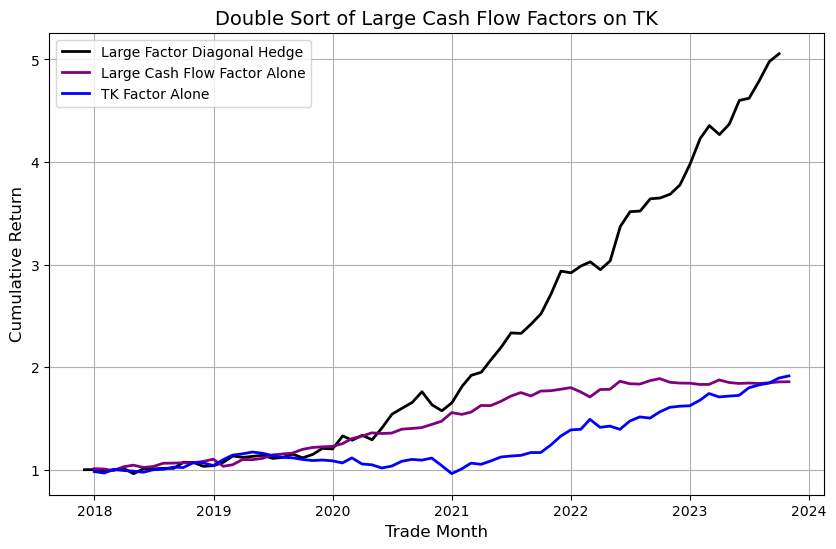

In [319]:
cumulative_large_highTK = (1 + TK_port3["5-5"] - TK_port3["5-1"]).cumprod()
cumulative_large_smallTK = (1 + TK_port3["1-5"] - TK_port3["1-1"]).cumprod()
cumulative_large_TKDiagonal = (1 + TK_port3['1-5'] - TK_port3['5-1']).cumprod()
cumulative_small_highTK = (1 + TK_port5["5-1"] - TK_port5["5-5"]).cumprod()
cumulative_small_smallTK = (1 + TK_port5["1-1"] - TK_port5["1-5"]).cumprod()
cumulative_small_TKDiagonal = (1 + TK_port5['1-1'] - TK_port5['5-5']).cumprod()

cumulative_large_highTK = cumulative_large_highTK[:-3]
cumulative_large_smallTK = cumulative_large_smallTK[:-3]
cumulative_large_TKDiagonal = cumulative_large_TKDiagonal[:-3]
cumulative_small_highTK = cumulative_small_highTK[:-3]
cumulative_small_smallTK = cumulative_small_smallTK[:-3]
cumulative_small_TKDiagonal = cumulative_small_TKDiagonal[:-3]

cumulative_large_highTK.index = pd.to_datetime(cumulative_large_highTK.index, format='%Y-%m')
cumulative_large_smallTK.index = pd.to_datetime(cumulative_large_smallTK.index, format='%Y-%m')
cumulative_large_TKDiagonal.index = pd.to_datetime(cumulative_large_TKDiagonal.index, format='%Y-%m')
cumulative_small_highTK.index = pd.to_datetime(cumulative_small_highTK.index, format='%Y-%m')
cumulative_small_smallTK.index = pd.to_datetime(cumulative_small_smallTK.index, format='%Y-%m')
cumulative_small_TKDiagonal.index = pd.to_datetime(cumulative_small_TKDiagonal.index, format='%Y-%m')

# Plotting
plt.figure(figsize=(10, 6))

# Plot for TK_port2 (large factor)
# plt.plot(cumulative_large_highTK, label='Large Factor 5-1 (High TK)', color='blue', linestyle='-', linewidth=2)
# plt.plot(cumulative_large_smallTK, label='Large Factor 5-1 (Low TK)', color='green', linestyle='-', linewidth=2)
plt.plot(cumulative_large_TKDiagonal, label='Large Factor Diagonal Hedge', color='black', linestyle='-', linewidth=2)

stock_data_from_2017 = StockPicking7.loc['2017-12':]
cumulative_5_1_porf = (1 + stock_data_from_2017['5-1_porf']).cumprod()
cumulative_5_1_porf = cumulative_5_1_porf.loc[:'2023-12']

cumulative_TK_porf = singleTK.loc['2017-12':]
cumulative_TK_porf = (1 + singleTK['1-5_porf']).cumprod()
cumulative_TK_porf = cumulative_TK_porf.loc[:'2023-12']

plt.plot(cumulative_5_1_porf, label='Large Cash Flow Factor Alone', color='purple', linestyle='-', linewidth=2)
plt.plot(cumulative_TK_porf, label='TK Factor Alone', color='blue', linestyle='-', linewidth=2)

# Adding labels and title
plt.title('Double Sort of Large Cash Flow Factors on TK', fontsize=14)
plt.xlabel('Trade Month', fontsize=12)
plt.ylabel('Cumulative Return', fontsize=12)
plt.legend(loc='best')

# Display the plot
plt.grid(True)
plt.show()

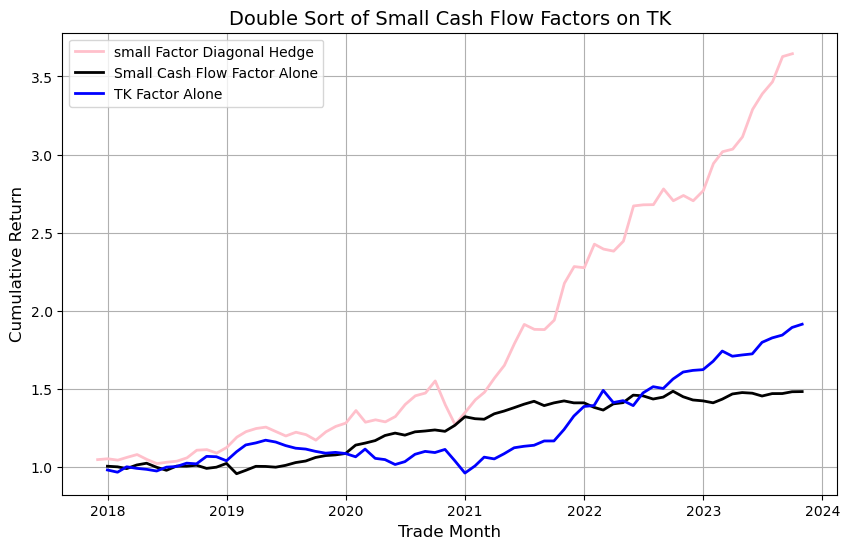

In [315]:
# Plotting
plt.figure(figsize=(10, 6))

# Plot for TK_port3 (small factor)
# plt.plot(cumulative_small_highTK, label='Small Factor 1-5 (High TK)', color='red', linestyle='-', linewidth=2)
# plt.plot(cumulative_small_smallTK, label='Small Factor 1-5 (Low TK)', color='orange', linestyle='-', linewidth=2)
plt.plot(cumulative_small_TKDiagonal, label='small Factor Diagonal Hedge', color='pink', linestyle='-', linewidth=2)

stock_data_from_2017 = StockPicking8.loc['2017-12':]
cumulative_5_1_porf = (1 + stock_data_from_2017['1-5_porf']).cumprod()
cumulative_5_1_porf = cumulative_5_1_porf.loc[:'2023-12']

plt.plot(cumulative_5_1_porf, label='Small Cash Flow Factor Alone', color='black', linestyle='-', linewidth=2)
plt.plot(cumulative_TK_porf, label='TK Factor Alone', color='blue', linestyle='-', linewidth=2)

# Adding labels and title
plt.title('Double Sort of Small Cash Flow Factors on TK', fontsize=14)
plt.xlabel('Trade Month', fontsize=12)
plt.ylabel('Cumulative Return', fontsize=12)
plt.legend(loc='best')

# Display the plot
plt.grid(True)
plt.show()

## TK_60Day

In [136]:
# TK_daily = pd.merge(
#     ThreeFactor,
#     Price1[['trade_dt', 's_info_windcode', 's_dq_open']],
#     on=['trade_dt', 's_info_windcode'],
#     how='left'
# )

# TK_daily['next_day_open'] = TK_daily.groupby('s_info_windcode')['s_dq_open'].shift(-1)

# TK_daily['Return'] = (TK_daily['next_day_open'] / TK_daily['s_dq_open']) - 1

# TK_daily['TK'] = TK_daily.groupby('s_info_windcode')['Return'].transform(lambda x: x.rolling(window=60, min_periods=60)
#                                                         .apply(lambda x: calculate_TK_for_month_final(x, v, w_minus, w_plus), raw=False))

# TK_daily = TK_daily.dropna(subset=['TK'])

# TK_daily = TK_daily[TK_daily['exclude'] != 1]


# TK_daily

In [137]:
# TK_daily_port = TK_daily.copy()

# TK_daily_port = TK_daily_port.groupby([TK_daily_port['trade_dt'].dt.to_period('M'), 's_info_windcode'], as_index=False).last()
# TK_daily_port['trade_month'] = TK_daily_port['trade_dt'].dt.to_period('M')
# TK_daily_port = TK_daily_port.drop(columns=['trade_dt'])

# TK_daily_port['Return_next_month'] = TK_daily_port.groupby('s_info_windcode')['Return'].shift(-1)
# TK_daily_port = TK_daily_port.dropna(subset=['Return_next_month'])

# TK_daily_port['TK_Porf'] = TK_daily_port.groupby('trade_month')['TK'].transform(custom_qcut)
# TK_daily_port['large_factor2_Porf'] = TK_daily_port.groupby(['trade_month', 'TK_Porf'])['large_factor2'].transform(lambda x: pd.qcut(x, q=5, labels=False) + 1)
# TK_daily_port['small_factor2_Porf'] = TK_daily_port.groupby(['trade_month', 'TK_Porf'])['small_factor2'].transform(lambda x: pd.qcut(x, q=5, labels=False) + 1)

# TK_daily_port

In [138]:
# TK_daily_port1 = TK_daily_port.copy()

# TK_daily_port1 = TK_daily_port1.drop(columns=['s_info_windcode', 'exclude', 'large_factor', 'large_factor1', 'large_factor2',
#                                   'small_factor', 'small_factor1', 'small_factor2', 'Return', 'TK'])

# TK_daily_port1['large_Port_Return'] = TK_daily_port1.groupby(['trade_month', 'TK_Porf', 'large_factor2_Porf'])['Return_next_day'].transform('mean')
# TK_daily_port1['small_Port_Return'] = TK_daily_port1.groupby(['trade_month', 'TK_Porf', 'small_factor2_Porf'])['Return_next_day'].transform('mean')

# TK_daily_port1

In [139]:
# TK_daily_port2 = TK_daily_port1.copy()

# TK_daily_port2 = TK_daily_port2.drop_duplicates(subset=['trade_month', 'TK_Porf', 'large_factor2_Porf'])

# TK_daily_port2['large_factor2_Porf'] = (
#     TK_daily_port2['TK_Porf'].astype(str) + '-' + TK_daily_port2['large_factor2_Porf'].astype(str)
# )

# TK_daily_port2 = TK_daily_port2.drop(columns=['Return_next_month', 'small_factor2_Porf', 'small_Port_Return', 'TK_Porf'])
    
# TK_daily_port2

In [140]:
# TK_daily_port3 = TK_daily_port2.copy()

# TK_daily_port3 = TK_daily_port3.pivot(index='trade_month', columns='large_factor2_Porf', values='large_Port_Return')

# TK_daily_port3[1] = TK_daily_port3['5-5'] - TK_daily_port3['1-1']

# cumulative_porf_return = TK_daily_port3.apply(lambda x: (1 + x).cumprod().iloc[-1], axis=0)

# TK_daily_port3.loc['Cumulative_porf_return'] = cumulative_porf_return

# average_return = TK_daily_port3.drop('Cumulative_porf_return', axis=0).mean()

# TK_daily_port3.loc['Average_return'] = average_return

# t_values = []

# for col in TK_daily_port3.columns:
#     data = TK_daily_port3[col].drop(index=['Cumulative_porf_return', 'Average_return'], errors='ignore')
        
#     x_bar = np.mean(data)
#     s = np.std(data, ddof=1)
#     n = len(data)
        
#     t_stat = (x_bar - 0) / s * np.sqrt(n)
        
#     t_values.append(t_stat)

# TK_daily_port3.loc['T_value_avg'] = t_values

# TK_daily_port3

## ST

In [255]:
ST = Price1.copy()

ST = ST[ST['trade_month'] >= '2017-12']

ST = ST[ST['exclude'] != 1]

ST['daily_ret'] = ST.groupby('s_info_windcode')['s_dq_close'].pct_change()

ST = ST.drop(columns=['s_dq_open',  's_dq_high', 's_dq_low', 's_dq_close',
                              's_dq_adjfactor',  's_dq_volume', 's_dq_amount', 's_dq_limit', 
                              's_dq_stopping', 's_dq_tradestatuscode', '20_ret', 
                              'is_st', 'limit_stop', 'exclude'])

ST = ST.dropna(subset=['daily_ret'])

ST['daily_mkt_Ret'] = ST.groupby('trade_dt')['daily_ret'].transform('mean')

ST['Salience'] = np.abs(ST['daily_ret'] - ST['daily_mkt_Ret']) / (
            np.abs(ST['daily_ret']) + np.abs(ST['daily_mkt_Ret']) + 0.1)

ST = ST.groupby(['trade_month', 's_info_windcode']).apply(calculate_salience_weight).reset_index(drop=True)
ST = ST.groupby(['trade_month', 's_info_windcode']).apply(calculate_st_value).reset_index(drop=True)

ST

C:\Users\yangh\AppData\Local\Temp\ipykernel_7932\3051438964.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ST = ST.groupby(['trade_month', 's_info_windcode']).apply(calculate_salience_weight).reset_index(drop=True)
C:\Users\yangh\AppData\Local\Temp\ipykernel_7932\3051438964.py:20: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ST = ST.groupby(['trade_month', 's_info_windcode']).apply(calculate_st_value).reset_in

,trade_dt,s_info_windcode,trade_month,daily_ret,daily_mkt_Ret,Salience,Rank,Salience_Weight,ST_value
0,2013-01-07,000001.SZ,2013-01,0.019387,0.011069,0.063765,11.0,0.144398,1.226217
1,2013-01-08,000001.SZ,2013-01,-0.018405,0.010959,0.226986,5.0,1.227365,1.226217
2,2013-01-09,000001.SZ,2013-01,-0.008750,0.001712,0.094713,10.0,0.206283,1.226217
3,2013-01-10,000001.SZ,2013-01,0.000631,0.006075,0.051022,13.0,0.070755,1.226217
4,2013-01-11,000001.SZ,2013-01,-0.020794,-0.019723,0.007623,17.0,0.016988,1.226217
...,...,...,...,...,...,...,...,...,...
9047091,2023-12-25,689009.SH,2023-12,-0.031552,-0.004037,0.202932,4.0,2.162108,-0.516537
9047092,2023-12-26,689009.SH,2023-12,-0.074136,-0.014019,0.319509,1.0,6.303521,-0.516537
9047093,2023-12-27,689009.SH,2023-12,0.037343,0.007821,0.203370,3.0,3.088725,-0.516537
9047094,2023-12-28,689009.SH,2023-12,0.010730,0.018757,0.061991,14.0,0.061074,-0.516537


In [259]:
ST1 = ST.copy()

ST1 = ST1[ST1['trade_month'] >= '2017-12']

ST1 = ST1.drop_duplicates(subset=['s_info_windcode', 'trade_month'])
                                              
ST1 = ST1.drop(columns=['trade_dt', 'Salience_Weight', 'Rank', 'daily_ret', 'daily_mkt_Ret', 'Salience'])

ST1

,s_info_windcode,trade_month,ST_value
3128620,000001.SZ,2017-12,0.083222
3128641,000002.SZ,2017-12,0.195641
3128662,000004.SZ,2017-12,-0.571262
3128683,000005.SZ,2017-12,-0.039022
3128704,000006.SZ,2017-12,0.000000
...,...,...,...
9046991,688799.SH,2023-12,0.620652
9047012,688800.SH,2023-12,-0.053669
9047033,688819.SH,2023-12,0.082086
9047054,688981.SH,2023-12,-0.222116


In [261]:
singleST = backtest(ST1, PriceMonthly, 'ST_value')

singleST

ST_value_porf,1,2,3,4,5,5-1_porf,1-5_porf,cumulative_5-1_porf,cumulative_1-5_porf
trade_month,,,,,,,,,
2017-12,-0.036153,-0.024380,-0.029579,-0.029792,-0.040531,-0.004379,0.004379,0.995621,1.004379
2018-01,-0.039325,-0.048097,-0.052044,-0.056852,-0.061330,-0.022005,0.022005,0.973713,1.026480
2018-02,0.097088,0.071250,0.033639,0.045377,0.061232,-0.035856,0.035856,0.938800,1.063285
2018-03,-0.040470,-0.035791,-0.037806,-0.039839,-0.050953,-0.010483,0.010483,0.928958,1.074431
2018-04,-0.019690,-0.004774,-0.013908,-0.002705,-0.014082,0.005608,-0.005608,0.934168,1.068406
...,...,...,...,...,...,...,...,...,...
2023-06,0.010638,0.043305,0.025367,0.007396,-0.044854,-0.055492,0.055492,0.536291,1.739289
2023-07,-0.033467,-0.036496,-0.038399,-0.043607,-0.034009,-0.000542,0.000542,0.536000,1.740232
2023-08,-0.005235,0.001729,-0.000631,0.003700,-0.025021,-0.019786,0.019786,0.525395,1.774664


In [263]:
ST2 = pd.merge(
    ThreeFactorMonthly,
    PriceMonthly[['trade_month', 's_info_windcode', 'Return']],
    on=['trade_month', 's_info_windcode'],
    how='left'
)

ST2['Return_next_month'] = ST2.groupby('s_info_windcode')['Return'].shift(-1)
ST2 = ST2.dropna(subset=['Return_next_month'])

ST2 = ST2[ST2['exclude'] != 1]

ST2

,s_info_windcode,exclude,large_factor,small_factor,large_factor1,small_factor1,large_factor2,small_factor2,trade_month,Return,Return_next_month
0,000001.SZ,0,0.001266,-0.011980,0.002191,-0.036779,0.063459,-0.430726,2013-01,0.287990,0.090866
1,000004.SZ,0,-0.012220,0.010571,-0.045558,0.011898,-0.210799,0.169787,2013-01,0.137973,0.079399
2,000005.SZ,0,-0.018850,0.004941,-0.064670,0.005061,-0.428923,0.074983,2013-01,0.046823,-0.041534
3,000006.SZ,0,-0.007478,0.001910,-0.015260,0.002820,-0.224489,0.058804,2013-01,0.105578,-0.063063
5,000009.SZ,0,0.001783,0.001264,0.003372,0.002040,0.092674,0.052274,2013-01,0.094701,-0.062822
...,...,...,...,...,...,...,...,...,...,...,...
446539,688798.SH,0,0.017457,0.000645,0.069228,0.000648,0.561616,0.012708,2023-10,0.254810,-0.070747
446540,688799.SH,0,-0.010616,-0.026766,-0.026986,-0.029951,-0.198686,-0.469049,2023-10,0.165808,-0.042735
446541,688800.SH,0,0.022161,-0.018254,0.055895,-0.021671,0.698745,-0.434139,2023-10,-0.003793,0.110406
446542,688819.SH,0,0.001767,-0.019525,0.011559,-0.015167,0.052988,-0.240422,2023-10,-0.082094,-0.077594


In [265]:
ST3 = pd.merge(
    ST2,
    ST1[['trade_month', 's_info_windcode', 'ST_value']],
    on=['trade_month', 's_info_windcode'],
    how='left'
)

ST3 = ST3.drop(columns=['exclude'])

ST3 = ST3.dropna(subset=['ST_value'])

PCAdata = ST3.copy()

ST3['ST_Porf'] = ST3.groupby('trade_month')['ST_value'].transform(custom_qcut)
ST3['large_factor2_Porf'] = ST3.groupby(['trade_month', 'ST_Porf'])['large_factor2'].transform(lambda x: pd.qcut(x, q=5, labels=False) + 1)
ST3['small_factor2_Porf'] = ST3.groupby(['trade_month', 'ST_Porf'])['small_factor2'].transform(lambda x: pd.qcut(x, q=5, labels=False) + 1)

ST4 = ST3.copy()

ST3 = ST3.drop(columns=['s_info_windcode', 'large_factor', 'large_factor1', 'large_factor2',
                                  'small_factor', 'small_factor1', 'small_factor2', 'Return', 'ST_value'])

ST3['large_Port_Return'] = ST3.groupby(['trade_month', 'ST_Porf', 'large_factor2_Porf'])['Return_next_month'].transform('mean')
ST3['small_Port_Return'] = ST3.groupby(['trade_month', 'ST_Porf', 'small_factor2_Porf'])['Return_next_month'].transform('mean')

ST3

,trade_month,Return_next_month,ST_Porf,large_factor2_Porf,small_factor2_Porf,large_Port_Return,small_Port_Return
147291,2017-12,0.044944,3,5,3,-0.016481,-0.027255
147292,2017-12,0.192369,4,4,3,-0.024828,-0.021366
147293,2017-12,-0.093764,1,3,1,-0.050846,-0.044163
147294,2017-12,-0.033735,3,1,5,-0.013420,-0.029195
147295,2017-12,-0.054857,2,3,1,-0.034521,-0.038453
...,...,...,...,...,...,...,...
427648,2023-10,-0.070747,5,5,2,0.048886,0.027479
427649,2023-10,-0.042735,5,3,1,0.040324,0.055571
427650,2023-10,0.110406,5,5,1,0.048886,0.055571
427651,2023-10,-0.077594,2,5,1,0.023277,0.024748


In [271]:
ST_port1 = ST3.copy()

ST_port1 = ST_port1.drop_duplicates(subset=['trade_month', 'ST_Porf', 'large_factor2_Porf'])

ST_port1['large_factor2_Porf'] = (
    ST_port1['ST_Porf'].astype(str) + '-' + ST_port1['large_factor2_Porf'].astype(str)
)

ST_port1 = ST_port1.drop(columns=['Return_next_month', 'small_factor2_Porf', 'small_Port_Return'])

ST_port1 = ST_port1.pivot(index='trade_month', columns='large_factor2_Porf', values='large_Port_Return')

ST_port1[1] = ST_port1['1-5'] - ST_port1['5-1']

cumulative_porf_return = ST_port1.apply(lambda x: (1 + x).cumprod().iloc[-1], axis=0)

ST_port1.loc['Cumulative_porf_return'] = cumulative_porf_return

average_return = ST_port1.drop('Cumulative_porf_return', axis=0).mean()

ST_port1.loc['Average_return'] = average_return

t_values = []

for col in ST_port1.columns:
    data = ST_port1[col].drop(index=['Cumulative_porf_return', 'Average_return'], errors='ignore')
        
    x_bar = np.mean(data)
    s = np.std(data, ddof=1)
    n = len(data)
        
    t_stat = (x_bar - 0) / s * np.sqrt(n)
        
    t_values.append(t_stat)

ST_port1.loc['T_value_avg'] = t_values

ST_port1

large_factor2_Porf,1-1,1-2,1-3,1-4,1-5,2-1,2-2,2-3,2-4,2-5,3-1,3-2,3-3,3-4,3-5,4-1,4-2,4-3,4-4,4-5,5-1,5-2,5-3,5-4,5-5,1
trade_month,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-12,-0.037085,-0.032126,-0.050846,-0.029355,-0.037103,-0.032269,-0.022429,-0.034521,-0.029655,-0.041195,-0.013420,-0.039782,-0.024609,-0.027101,-0.016481,-0.051423,-0.046733,-0.014563,-0.024828,-0.017888,-0.075828,-0.070814,-0.046061,-0.029713,-0.027011,0.038725
2018-01,-0.037972,-0.008839,-0.035351,-0.028342,-0.063382,-0.049707,-0.052408,-0.049796,-0.064378,-0.047184,-0.056491,-0.050232,-0.052256,-0.057820,-0.051616,-0.057495,-0.064717,-0.059942,-0.058107,-0.053797,-0.082763,-0.081960,-0.062112,-0.026215,-0.052264,0.019380
2018-02,0.093082,0.124198,0.092958,0.110319,0.124701,0.074913,0.096792,0.071336,0.080102,0.067775,0.036992,0.060319,0.045207,0.050143,0.032131,0.066136,0.054391,0.059784,0.064712,0.017813,0.080545,0.050140,0.060087,0.054563,0.034660,0.044156
2018-03,-0.063046,-0.061977,-0.044257,-0.031473,-0.027258,-0.047516,-0.047125,-0.024363,-0.031270,-0.037481,-0.054040,-0.049091,-0.046692,-0.033449,-0.028238,-0.064840,-0.058767,-0.024437,-0.041910,-0.018165,-0.096364,-0.089795,-0.030688,-0.039036,-0.025080,0.069105
2018-04,-0.041135,-0.020354,-0.025881,-0.019271,-0.006913,-0.017176,-0.023651,-0.007247,-0.004150,-0.000820,-0.001715,-0.010297,-0.009760,-0.011598,-0.000918,-0.012028,-0.029013,-0.006495,0.003846,0.005502,-0.020598,0.002966,-0.040281,-0.028508,-0.013205,0.013685
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-09,-0.033348,-0.028854,-0.026185,-0.020699,-0.025361,-0.016338,-0.014252,-0.012961,-0.014606,-0.025613,-0.009023,-0.009226,-0.008048,-0.015970,-0.015281,0.006501,0.005287,-0.003146,0.002659,-0.000362,-0.014584,0.012256,-0.011810,0.025454,0.023100,-0.010777
2023-10,0.032437,0.035151,0.047494,0.038123,0.047839,0.027141,0.034565,0.033191,0.020537,0.023277,0.031451,0.045821,0.034763,0.034770,0.034146,0.054526,0.042927,0.039791,0.037463,0.030875,0.018176,0.015822,0.040324,0.032921,0.048886,0.029664
Cumulative_porf_return,0.727844,1.411638,1.825047,1.906200,1.743895,1.160718,1.538173,1.735835,1.921141,1.650811,1.172714,1.481503,1.641716,1.734175,1.668017,0.820945,1.056602,1.622595,1.609306,1.466713,0.182564,0.461524,0.820048,1.050010,1.131546,8.236911


In [273]:
ST_port2 = ST3.copy()

ST_port2 = ST_port2.drop_duplicates(subset=['trade_month', 'ST_Porf', 'small_factor2_Porf'])

ST_port2['small_factor2_Porf'] = (
    ST_port2['ST_Porf'].astype(str) + '-' + ST_port2['small_factor2_Porf'].astype(str)
)

ST_port2 = ST_port2.drop(columns=['Return_next_month', 'large_factor2_Porf', 'large_Port_Return'])

ST_port2 = ST_port2.pivot(index='trade_month', columns='small_factor2_Porf', values='small_Port_Return')

ST_port2[1] = ST_port2['1-1'] - ST_port2['5-5']

cumulative_porf_return = ST_port2.apply(lambda x: (1 + x).cumprod().iloc[-1], axis=0)

ST_port2.loc['Cumulative_porf_return'] = cumulative_porf_return

average_return = ST_port2.drop('Cumulative_porf_return', axis=0).mean()

ST_port2.loc['Average_return'] = average_return

t_values = []

for col in ST_port2.columns:
    data = ST_port2[col].drop(index=['Cumulative_porf_return', 'Average_return'], errors='ignore')
        
    x_bar = np.mean(data)
    s = np.std(data, ddof=1)
    n = len(data)
        
    t_stat = (x_bar - 0) / s * np.sqrt(n)
        
    t_values.append(t_stat)


ST_port2.loc['T_value_avg'] = t_values

ST_port2

small_factor2_Porf,1-1,1-2,1-3,1-4,1-5,2-1,2-2,2-3,2-4,2-5,3-1,3-2,3-3,3-4,3-5,4-1,4-2,4-3,4-4,4-5,5-1,5-2,5-3,5-4,5-5,1
trade_month,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-12,-0.044163,-0.043197,-0.035509,-0.042976,-0.020974,-0.038453,-0.026750,-0.033144,-0.034852,-0.026861,-0.021644,-0.017106,-0.027255,-0.026210,-0.029195,-0.008865,-0.029287,-0.021366,-0.045422,-0.050538,-0.043754,-0.015404,-0.040693,-0.075186,-0.074202,0.030039
2018-01,-0.049591,-0.052284,-0.025420,-0.027726,-0.018736,-0.053703,-0.058457,-0.054261,-0.049075,-0.047947,-0.044736,-0.056069,-0.065949,-0.056599,-0.045093,-0.050252,-0.051928,-0.073597,-0.061743,-0.056568,-0.035009,-0.044486,-0.073382,-0.085191,-0.067390,0.017799
2018-02,0.125568,0.117812,0.119527,0.088890,0.093112,0.048116,0.089286,0.107469,0.092985,0.053062,0.028892,0.041546,0.060142,0.063269,0.030995,0.021970,0.047649,0.063046,0.083808,0.046363,0.037117,0.056519,0.041867,0.069791,0.074973,0.050595
2018-03,-0.036708,-0.037986,-0.041810,-0.041767,-0.069538,-0.042498,-0.019504,-0.040174,-0.042468,-0.043211,-0.023593,-0.039095,-0.042325,-0.059146,-0.047324,-0.020534,-0.037850,-0.036939,-0.060591,-0.052284,-0.027393,-0.034439,-0.047925,-0.081956,-0.089309,0.052602
2018-04,-0.006201,-0.003784,-0.015113,-0.043484,-0.044972,-0.007719,-0.012627,-0.012069,-0.008362,-0.012297,-0.000574,-0.021166,-0.007570,-0.002592,-0.002371,0.010500,-0.013729,-0.008432,-0.021914,-0.004626,-0.011202,-0.039444,-0.028327,-0.016719,-0.003935,-0.002266
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-09,-0.025661,-0.016577,-0.035400,-0.026231,-0.030578,-0.024752,-0.015291,-0.009228,-0.017271,-0.017242,-0.017724,-0.008558,-0.010864,-0.008466,-0.011902,0.003581,-0.005118,-0.002464,0.008460,0.006463,0.031368,0.006741,0.002344,0.000298,-0.006222,-0.019439
2023-10,0.054452,0.032564,0.044929,0.018849,0.050250,0.024748,0.027383,0.034921,0.025124,0.026534,0.038413,0.037953,0.035334,0.033293,0.035958,0.034293,0.042802,0.037967,0.041091,0.049428,0.055571,0.027479,0.022155,0.044011,0.006913,0.047540
Cumulative_porf_return,2.219472,1.946182,1.542990,0.986479,0.941264,1.678618,1.874934,1.841637,1.495184,1.131938,1.752707,1.734033,1.449400,1.387517,1.348612,1.667330,1.414621,1.317917,1.088900,0.982360,1.170579,0.895320,0.566544,0.376983,0.373106,5.369226


In [275]:
print(ST_port1.tail(3))

large_factor2_Porf           1-1       1-2       1-3       1-4       1-5  \
trade_month                                                                
Cumulative_porf_return  0.727844  1.411638  1.825047  1.906200  1.743895   
Average_return         -0.001935  0.007420  0.011093  0.011649  0.010268   
T_value_avg            -0.224587  0.852019  1.273038  1.352207  1.223878   

large_factor2_Porf           2-1       2-2       2-3       2-4       2-5  \
trade_month                                                                
Cumulative_porf_return  1.160718  1.538173  1.735835  1.921141  1.650811   
Average_return          0.004416  0.008254  0.009823  0.011216  0.008936   
T_value_avg             0.536878  1.036774  1.274416  1.475250  1.215885   

large_factor2_Porf           3-1       3-2       3-3       3-4       3-5  \
trade_month                                                                
Cumulative_porf_return  1.172714  1.481503  1.641716  1.734175  1.668017   
Average_re

In [277]:
print(ST_port2.tail(3))

small_factor2_Porf           1-1       1-2       1-3       1-4       1-5  \
trade_month                                                                
Cumulative_porf_return  2.219472  1.946182  1.542990  0.986479  0.941264   
Average_return          0.013741  0.012033  0.008634  0.002388  0.001622   
T_value_avg             1.616080  1.374115  1.008976  0.273691  0.189421   

small_factor2_Porf           2-1       2-2       2-3       2-4       2-5  \
trade_month                                                                
Cumulative_porf_return  1.678618  1.874934  1.841637  1.495184  1.131938   
Average_return          0.009174  0.010911  0.010705  0.007847  0.003996   
T_value_avg             1.249521  1.417473  1.374835  0.986152  0.493312   

small_factor2_Porf           3-1       3-2       3-3       3-4       3-5  \
trade_month                                                                
Cumulative_porf_return  1.752707  1.734033  1.449400  1.387517  1.348612   
Average_re

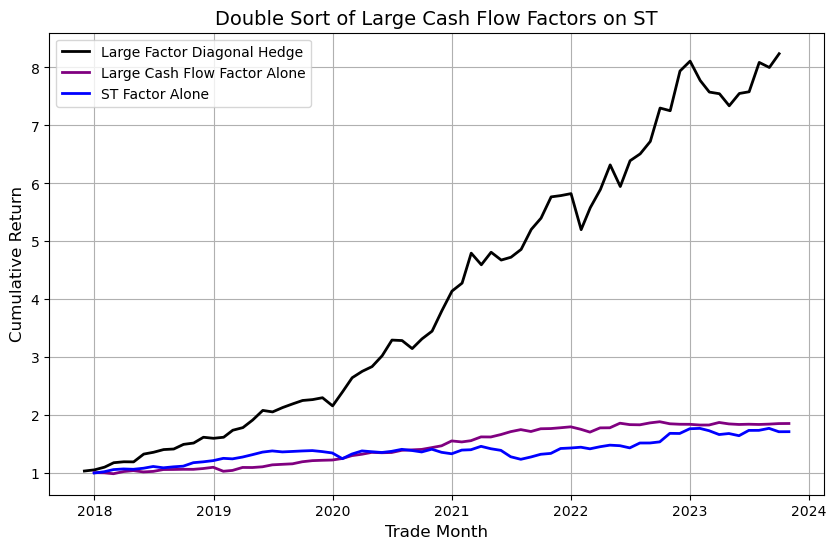

In [321]:
# cumulative_large_highST = (1 + ST_port1["5-5"] - ST_port1["5-1"]).cumprod()
# cumulative_large_smallST = (1 + ST_port1["1-5"] - ST_port1["1-1"]).cumprod()
cumulative_large_STDiagonal = (1 + ST_port1['1-5'] - ST_port1['5-1']).cumprod()
# cumulative_small_highST = (1 + ST_port2["5-1"] - ST_port2["5-5"]).cumprod()
# cumulative_small_smallST = (1 + ST_port2["1-1"] - ST_port2["1-5"]).cumprod()
cumulative_small_STDiagonal = (1 + ST_port2['1-1'] - ST_port2['5-5']).cumprod()

# cumulative_large_highST = cumulative_large_highST[:-3]
# cumulative_large_smallST = cumulative_large_smallST[:-3]
cumulative_large_STDiagonal = cumulative_large_STDiagonal[:-3]
# cumulative_small_highST = cumulative_small_highST[:-3]
# cumulative_small_smallST = cumulative_small_smallST[:-3]
cumulative_small_STDiagonal = cumulative_small_STDiagonal[:-3]

# cumulative_large_highST.index = pd.to_datetime(cumulative_large_highST.index, format='%Y-%m')
# cumulative_large_smallST.index = pd.to_datetime(cumulative_large_smallST.index, format='%Y-%m')
cumulative_large_STDiagonal.index = pd.to_datetime(cumulative_large_STDiagonal.index, format='%Y-%m')
# cumulative_small_highST.index = pd.to_datetime(cumulative_small_highST.index, format='%Y-%m')
# cumulative_small_smallST.index = pd.to_datetime(cumulative_small_smallST.index, format='%Y-%m')
cumulative_small_STDiagonal.index = pd.to_datetime(cumulative_small_STDiagonal.index, format='%Y-%m')

plt.figure(figsize=(10, 6))

# Plot for ST_port1 (large factor)
# plt.plot(cumulative_large_highST, label='Large Factor 5-1 (High ST)', color='blue', linestyle='-', linewidth=2)
# plt.plot(cumulative_large_smallST, label='Large Factor 5-1 (Low ST)', color='green', linestyle='-', linewidth=2)
plt.plot(cumulative_large_STDiagonal, label='Large Factor Diagonal Hedge', color='black', linestyle='-', linewidth=2)

stock_data_from_2013 = StockPicking7.loc['2017-12':]
cumulative_5_1_porf = (1 + stock_data_from_2013['5-1_porf']).cumprod()
cumulative_5_1_porf = cumulative_5_1_porf.loc[:'2023-12']

cumulative_ST_porf = singleST.loc['2017-12':]
cumulative_ST_porf = (1 + singleST['1-5_porf']).cumprod()
cumulative_ST_porf = cumulative_ST_porf.loc[:'2023-12']

plt.plot(cumulative_5_1_porf, label='Large Cash Flow Factor Alone', color='purple', linestyle='-', linewidth=2)
plt.plot(cumulative_ST_porf, label='ST Factor Alone', color='blue', linestyle='-', linewidth=2)

# Adding labels and title
plt.title('Double Sort of Large Cash Flow Factors on ST', fontsize=14)
plt.xlabel('Trade Month', fontsize=12)
plt.ylabel('Cumulative Return', fontsize=12)
plt.legend(loc='best')

# Display the plot
plt.grid(True)
plt.show()

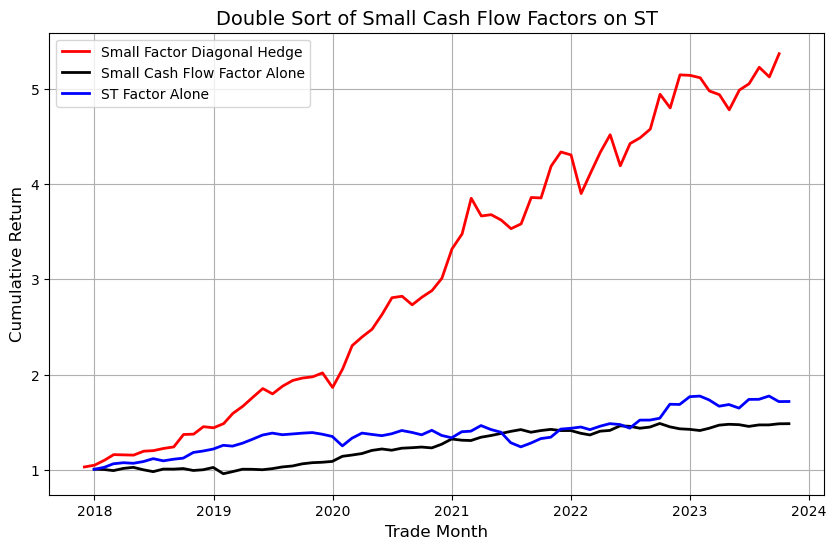

In [307]:
# Plotting
plt.figure(figsize=(10, 6))

# Plot for ST_port2 (small factor)
# plt.plot(cumulative_small_highST, label='Small Factor 1-5 (High ST)', color='pink', linestyle='-', linewidth=2)
# plt.plot(cumulative_small_smallST, label='Small Factor 1-5 (Low ST)', color='orange', linestyle='-', linewidth=2)
plt.plot(cumulative_small_STDiagonal, label='Small Factor Diagonal Hedge', color='red', linestyle='-', linewidth=2)

stock_data_from_2013 = StockPicking8.loc['2017-12':]
cumulative_5_1_porf = (1 + stock_data_from_2013['1-5_porf']).cumprod()
cumulative_5_1_porf = cumulative_5_1_porf.loc[:'2023-12']

plt.plot(cumulative_5_1_porf, label='Small Cash Flow Factor Alone', color='black', linestyle='-', linewidth=2)
plt.plot(cumulative_ST_porf, label='ST Factor Alone', color='blue', linestyle='-', linewidth=2)

# Adding labels and title
plt.title('Double Sort of Small Cash Flow Factors on ST', fontsize=14)
plt.xlabel('Trade Month', fontsize=12)
plt.ylabel('Cumulative Return', fontsize=12)
plt.legend(loc='best')

# Display the plot
plt.grid(True)
plt.show()